# 04 · Agricultural inventory optimization (Linear Programming)

**Decision:** for each crop, how many tonnes of the *derived 2025 closing stock* should we **sell now** and how many should we **hold for a hypothetical later sale**, given a limited warehouse capacity?

**Sources:** `data/agriculture/processed/agriculture_panel.csv` produced by notebook 02. Historical production costs and inventory flows come from form 50-сг. **Prices, future price changes, storage cost, crop space coefficients and warehouse capacity are explicitly illustrative assumptions**, **not observed figures**. This is an educational **prescriptive scenario**, not an actual sales recommendation.

**Link to lectures:** linear programming (decision variables, objective function, constraints), sensitivity / shadow prices, and prescriptive explainability. Unlike the separate forecasting notebooks, **this notebook does not assert forecasts for the agricultural data**.

**Important limitations:** tonnes are not cubic metres; stock is a *derived* balance (`opening + inflow − outflow`), not a verified measured warehouse stock. No crop sales-demand, transport, quality, financing, or storage-deterioration constraints are available. The model assumes all allocated amounts can ultimately be sold and no price impact. Historical production costs are sunk for this allocation decision and must not be double-counted.

## 0 · Environment and paths
Run locally from the repository root or from `notebooks/` after notebook 02. Outputs are stored under `outputs/agriculture_optimization/`.

In [1]:
%pip -q install "pandas>=2.0,<3" "numpy>=1.26,<3" "scipy>=1.11,<2" "matplotlib>=3.7,<4"


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from IPython.display import display, Markdown

CWD = Path.cwd()
ROOT = CWD.parent if CWD.name == "notebooks" else CWD
DATA = ROOT / "data" / "agriculture" / "processed"
OUT = ROOT / "outputs" / "agriculture_optimization"
OUT.mkdir(parents=True, exist_ok=True)
panel_path = DATA / "agriculture_panel.csv"
if not panel_path.exists():
    raise FileNotFoundError(f"{panel_path} is missing. Run 02_agriculture_costs_inventory.ipynb locally first.")
panel = pd.read_csv(panel_path, encoding="utf-8-sig")
required = {"year","crop","opening_stock_tonnes","inflow_tonnes","outflow_tonnes", "ending_stock_derived_tonnes"}
if not required.issubset(panel.columns):
    raise ValueError(f"Missing columns: {sorted(required-set(panel.columns))}")
print("Data:", panel_path)
print("Output:", OUT)
print("Panel:", panel.shape, "| years:", sorted(panel.year.unique()))

Data: /Users/margopaduchak/Desktop/прогнози/forecasting-and-decision-optimization/data/agriculture/processed/agriculture_panel.csv
Output: /Users/margopaduchak/Desktop/прогнози/forecasting-and-decision-optimization/outputs/agriculture_optimization
Panel: (30, 20) | years: [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


## 1 · Validate historical inventory inputs
For 2025, require an unambiguous row per crop, non-negative closing stock, complete opening/inflow/outflow, and arithmetic consistency. If an extraction/QA issue affects the selected rows, **stop and review the PDF**. We do not fill missing stocks with zero.

In [3]:
YEAR = 2025
inventory_cols = ["opening_stock_tonnes", "inflow_tonnes", "outflow_tonnes", "ending_stock_derived_tonnes"]
selected = panel.loc[panel["year"].eq(YEAR), ["year","crop"] + inventory_cols].copy()
if selected.empty: raise ValueError(f"No year {YEAR} in panel")
if selected["crop"].duplicated().any(): raise ValueError("Duplicate crops in 2025 panel")
for name in inventory_cols:
    selected[name] = pd.to_numeric(selected[name], errors="coerce")
if selected[inventory_cols].isna().any().any():
    raise ValueError("2025 contains missing inventory fields; review extraction before optimizing")
if (selected[inventory_cols] < 0).any().any():
    raise ValueError("Negative inventory input: verify source and model assumptions")
recalculated = selected.opening_stock_tonnes + selected.inflow_tonnes - selected.outflow_tonnes
if not np.allclose(selected.ending_stock_derived_tonnes, recalculated, atol=0.11, rtol=0):
    raise ValueError("Closing stock does not match opening + inflow − outflow")
selected = selected.sort_values("crop").reset_index(drop=True)
selected["available_tonnes"] = selected["ending_stock_derived_tonnes"]
assert selected.available_tonnes.sum() > 0
print("Available 2025 closing stock (derived), tonnes:", f"{selected.available_tonnes.sum():,.1f}")
display(selected[["crop", "available_tonnes", "opening_stock_tonnes", "inflow_tonnes", "outflow_tonnes"]])

Available 2025 closing stock (derived), tonnes: 37,399.5


,crop,available_tonnes,opening_stock_tonnes,inflow_tonnes,outflow_tonnes
0,barley,2524.6,3576.0,4821.4,5872.8
1,maize,13297.2,9638.0,13673.9,10014.7
2,rapeseed,7851.6,6086.9,3599.2,1834.5
3,soybeans,3171.4,5427.9,2042.6,4299.1
4,sunflower,1393.3,1529.5,3258.8,3395.0
5,wheat,9161.4,7668.3,10309.5,8816.4


## 2 · Scenario assumptions (editable)
These illustrative numbers are **not observed in the PDF**. Prices (UAH/tonne) are invented for demonstration, not sourced market quotes. Future prices are uncertain; the assumed price change is **not a forecast**. The storage-cost amount represents total incremental holding cost until the hypothetical later sale. `space_units_per_tonne` is a planning coefficient, **not measured m³**.

You can safely edit `ASSUMPTIONS` before rerunning the remaining cells. Historical production costs are deliberately excluded from the decision's objective because they have already been incurred.

In [4]:
# ASSUMPTIONS ONLY — illustrative educational values, NOT source facts or market forecasts.
ASSUMPTIONS = {
    "barley":    {"sell_now_price_uah_per_t": 6500,  "later_price_change_pct": 7,  "holding_cost_uah_per_t": 300, "space_units_per_tonne": 1.00},
    "maize":     {"sell_now_price_uah_per_t": 7200,  "later_price_change_pct": 6,  "holding_cost_uah_per_t": 310, "space_units_per_tonne": 1.05},
    "rapeseed":  {"sell_now_price_uah_per_t": 17500, "later_price_change_pct": 5,  "holding_cost_uah_per_t": 480, "space_units_per_tonne": 0.95},
    "soybeans":  {"sell_now_price_uah_per_t": 14500, "later_price_change_pct": 10, "holding_cost_uah_per_t": 420, "space_units_per_tonne": 1.00},
    "sunflower": {"sell_now_price_uah_per_t": 16500, "later_price_change_pct": 8,  "holding_cost_uah_per_t": 440, "space_units_per_tonne": 0.95},
    "wheat":     {"sell_now_price_uah_per_t": 7700,  "later_price_change_pct": 8,  "holding_cost_uah_per_t": 320, "space_units_per_tonne": 1.00},
}
MIN_RESERVE_FRACTION = 0.10  # illustrative minimum share of each crop to retain
CAPACITY_SHARE_OF_ALL_STOCK = 0.60  # illustrative fraction of warehouse space to retain

if set(selected.crop) != set(ASSUMPTIONS):
    raise ValueError(f"Assumption crops mismatch. Missing={set(selected.crop)-set(ASSUMPTIONS)}, unused={set(ASSUMPTIONS)-set(selected.crop)}")
assumptions = pd.DataFrame.from_dict(ASSUMPTIONS, orient="index").rename_axis("crop").reset_index()
scenario = selected[["crop", "available_tonnes"]].merge(assumptions, on="crop", validate="one_to_one")
scenario["sell_later_price_uah_per_t"] = scenario.sell_now_price_uah_per_t * (1 + scenario.later_price_change_pct / 100)
scenario["incremental_net_benefit_per_held_t_uah"] = (scenario.sell_later_price_uah_per_t
    - scenario.sell_now_price_uah_per_t - scenario.holding_cost_uah_per_t)
scenario["min_hold_tonnes"] = MIN_RESERVE_FRACTION * scenario.available_tonnes
scenario["max_hold_tonnes"] = scenario.available_tonnes
# Reference capacity = a fraction of the planning-space required to hold ALL available crop stocks.
full_stock_space = float((scenario.available_tonnes * scenario.space_units_per_tonne).sum())
WAREHOUSE_CAPACITY_SPACE_UNITS = CAPACITY_SHARE_OF_ALL_STOCK * full_stock_space
scenario["min_reserve_space_units"] = scenario.min_hold_tonnes * scenario.space_units_per_tonne
assert WAREHOUSE_CAPACITY_SPACE_UNITS >= scenario.min_reserve_space_units.sum() - 1e-8, "Infeasible: capacity below mandatory reserves"
print(f"Capacity = {WAREHOUSE_CAPACITY_SPACE_UNITS:,.1f} PLANNING space units ({CAPACITY_SHARE_OF_ALL_STOCK:.0%} of full-stock space)")
print(f"Mandatory minimum reserves = {scenario.min_reserve_space_units.sum():,.1f} planning space units")
display(scenario.round(2))

Capacity = 22,561.3 PLANNING space units (60% of full-stock space)
Mandatory minimum reserves = 3,760.2 planning space units


,crop,available_tonnes,sell_now_price_uah_per_t,later_price_change_pct,holding_cost_uah_per_t,space_units_per_tonne,sell_later_price_uah_per_t,incremental_net_benefit_per_held_t_uah,min_hold_tonnes,max_hold_tonnes,min_reserve_space_units
0,barley,2524.6,6500,7,300,1.00,6955.0,155.0,252.46,2524.6,252.46
1,maize,13297.2,7200,6,310,1.05,7632.0,122.0,1329.72,13297.2,1396.21
2,rapeseed,7851.6,17500,5,480,0.95,18375.0,395.0,785.16,7851.6,745.90
3,soybeans,3171.4,14500,10,420,1.00,15950.0,1030.0,317.14,3171.4,317.14
4,sunflower,1393.3,16500,8,440,0.95,17820.0,880.0,139.33,1393.3,132.36
5,wheat,9161.4,7700,8,320,1.00,8316.0,296.0,916.14,9161.4,916.14


## 3 · LP formulation
Let \(q_i\) be available tonnes of crop \(i\), and \(x_i\) tonnes **held** for a hypothetical later sale. Tonnes sold now = \(q_i-x_i\).

Maximize the full hypothetical net revenue:

\[\max_x\ \sum_i p_i^{now}(q_i-x_i)+\sum_i (p_i^{later}-h_i)x_i\]

which, after subtracting the constant \(\sum_i p_i^{now}q_i\), is equivalent to:

\[\max_x \ \sum_i \underbrace{(p_i^{later}-p_i^{now}-h_i)}_{m_i}x_i.\]

Subject to:\[r_i q_i\le x_i\le q_i,\quad \sum_i a_ix_i\le C.\]

Here \(a_i\) is a **space planning coefficient**, \(C\) is the assumed capacity, and \(r_i\) the assumed minimum-reserve percentage. No uncertainty/price impact is modeled in this deterministic LP. We use `scipy.optimize.linprog(method="highs")`.

In [5]:
def optimize_allocation(df, capacity_space_units):
    """Solve the deterministic linear program; no implicit data/price assumptions."""
    q = df["available_tonnes"].to_numpy(float)
    margin = df["incremental_net_benefit_per_held_t_uah"].to_numpy(float)
    space = df["space_units_per_tonne"].to_numpy(float)
    lower = df["min_hold_tonnes"].to_numpy(float)
    if not (np.isfinite(q).all() and np.isfinite(margin).all() and np.isfinite(space).all() and np.isfinite(lower).all()):
        raise ValueError("Non-finite LP input")
    if (space <= 0).any() or (q < 0).any() or (lower < 0).any() or (lower > q).any():
        raise ValueError("Invalid bounds or space coefficients")
    if capacity_space_units + 1e-7 < float(np.dot(space, lower)):
        raise ValueError("Infeasible mandatory reserves: need more warehouse capacity")
    # linprog MINIMIZES -margin*x
    res = linprog(c=-margin, A_ub=space[None,:], b_ub=[float(capacity_space_units)],
                  bounds=list(zip(lower,q)), method="highs")
    if not res.success:
        raise RuntimeError(f"LP failed: {res.message}")
    result = df.copy()
    result["hold_tonnes"] = np.clip(res.x, lower, q)
    result["sell_now_tonnes"] = q - result.hold_tonnes
    result["space_used_units"] = result.hold_tonnes * result.space_units_per_tonne
    result["revenue_now_uah"] = result.sell_now_tonnes * result.sell_now_price_uah_per_t
    result["future_net_revenue_uah"] = result.hold_tonnes * (result.sell_later_price_uah_per_t - result.holding_cost_uah_per_t)
    result["incremental_benefit_uah"] = result.hold_tonnes * result.incremental_net_benefit_per_held_t_uah
    result["lower_bound_active"] = np.isclose(result.hold_tonnes, lower, atol=1e-5)
    result["upper_bound_active"] = np.isclose(result.hold_tonnes, q, atol=1e-5)
    baseline_sell_all_uah = float(np.dot(q, result.sell_now_price_uah_per_t))
    total_net_revenue_uah = float((result.revenue_now_uah + result.future_net_revenue_uah).sum())
    capacity_used = float(result.space_used_units.sum())
    # scipy returns derivative of MINIMIZED objective (negative uplift) w.r.t. <= capacity.
    # Marginal benefit in UAH per EXTRA space unit = -marginal from minimization.
    shadow_value = float(max(0., -res.ineqlin.marginals[0]))
    diagnostics = {
       "solver_status": res.message,
       "capacity_space_units": float(capacity_space_units),
       "space_used_units": capacity_used,
       "unused_capacity_space_units": float(capacity_space_units - capacity_used),
       "capacity_binding": bool(np.isclose(capacity_used, capacity_space_units, atol=1e-5)),
       "capacity_shadow_value_uah_per_space_unit": shadow_value,
       "immediate_sale_baseline_uah": baseline_sell_all_uah,
       "optimized_net_revenue_uah": total_net_revenue_uah,
       "incremental_benefit_vs_immediate_sale_uah": total_net_revenue_uah - baseline_sell_all_uah,
       "mandatory_reserve_incremental_benefit_uah":float(np.dot(lower,margin)),
    }
    return result, diagnostics

allocation, stats = optimize_allocation(scenario, WAREHOUSE_CAPACITY_SPACE_UNITS)
print("Solver:", stats["solver_status"])
display(allocation[["crop","available_tonnes","min_hold_tonnes","hold_tonnes","sell_now_tonnes","space_used_units","incremental_net_benefit_per_held_t_uah","lower_bound_active","upper_bound_active"]].round(2))
display(pd.DataFrame([stats]).T.rename(columns={0:"value"}))

Solver: Optimization terminated successfully. (HiGHS Status 7: Optimal)


,crop,available_tonnes,min_hold_tonnes,hold_tonnes,sell_now_tonnes,space_used_units,incremental_net_benefit_per_held_t_uah,lower_bound_active,upper_bound_active
0,barley,2524.6,252.46,252.46,2272.14,252.46,155.0,True,False
1,maize,13297.2,1329.72,1329.72,11967.48,1396.21,122.0,True,False
2,rapeseed,7851.6,785.16,7851.60,0.00,7459.02,395.0,False,True
3,soybeans,3171.4,317.14,3171.40,0.00,3171.40,1030.0,False,True
4,sunflower,1393.3,139.33,1393.30,0.00,1323.64,880.0,False,True
5,wheat,9161.4,916.14,8958.55,202.85,8958.55,296.0,False,False


,value
solver_status,Optimization terminated successfully. (HiGHS S...
capacity_space_units,22561.269
space_used_units,22561.269
unused_capacity_space_units,-0.0
capacity_binding,True
capacity_shadow_value_uah_per_space_unit,296.0
immediate_sale_baseline_uah,389070270.0
optimized_net_revenue_uah,399517385.348
incremental_benefit_vs_immediate_sale_uah,10447115.348
mandatory_reserve_incremental_benefit_uah,1231937.38


## 4 · Explainability / prescriptive analytics
An LP allocation is transparent: crops with larger **net marginal benefit per unit of storage space** are prioritized until storage is exhausted (subject to minimum crop reserves and available tonnes). `shadow_value` indicates the **local** value of one additional space unit **at the current optimum**; it is *not* a global guarantee for large changes in capacity.

**Baseline caveat:** selling everything now is an economic comparison, not necessarily a **feasible** alternative under the illustrative 10% mandatory reserves. We also report the reserve-only feasible baseline.

In [6]:
explain = allocation[["crop","incremental_net_benefit_per_held_t_uah","space_units_per_tonne","hold_tonnes","available_tonnes","lower_bound_active","upper_bound_active"]].copy()
explain["benefit_per_space_unit_uah"] = explain.incremental_net_benefit_per_held_t_uah / explain.space_units_per_tonne
explain["held_share_pct"] = 100*explain.hold_tonnes / explain.available_tonnes
explain = explain.sort_values("benefit_per_space_unit_uah", ascending=False)
display(explain.round(2))
reserve_only_net = float(stats["immediate_sale_baseline_uah"] + stats["mandatory_reserve_incremental_benefit_uah"])
print(f"All-sell-now hypothetical benchmark: {stats['immediate_sale_baseline_uah']:,.0f} UAH (violates chosen min reserves)")
print(f"Feasible reserve-only benchmark: {reserve_only_net:,.0f} UAH")
print(f"Optimized total net revenue: {stats['optimized_net_revenue_uah']:,.0f} UAH")
print(f"Gain vs feasible reserve-only benchmark: {stats['optimized_net_revenue_uah']-reserve_only_net:,.0f} UAH")
print(f"Capacity utilization: {stats['space_used_units']/stats['capacity_space_units']:.1%}")
print(f"Local capacity shadow value: {stats['capacity_shadow_value_uah_per_space_unit']:,.2f} UAH per additional planning space unit")
if stats['capacity_binding']:
    print("Binding: warehouse capacity. Some product allocation is capacity-limited.")
else:
    print("Not binding: warehouse capacity is currently slack.")

,crop,incremental_net_benefit_per_held_t_uah,space_units_per_tonne,hold_tonnes,available_tonnes,lower_bound_active,upper_bound_active,benefit_per_space_unit_uah,held_share_pct
3,soybeans,1030.0,1.00,3171.40,3171.4,False,True,1030.00,100.00
4,sunflower,880.0,0.95,1393.30,1393.3,False,True,926.32,100.00
2,rapeseed,395.0,0.95,7851.60,7851.6,False,True,415.79,100.00
5,wheat,296.0,1.00,8958.55,9161.4,False,False,296.00,97.79
0,barley,155.0,1.00,252.46,2524.6,True,False,155.00,10.00
1,maize,122.0,1.05,1329.72,13297.2,True,False,116.19,10.00


All-sell-now hypothetical benchmark: 389,070,270 UAH (violates chosen min reserves)
Feasible reserve-only benchmark: 390,302,207 UAH
Optimized total net revenue: 399,517,385 UAH
Gain vs feasible reserve-only benchmark: 9,215,178 UAH
Capacity utilization: 100.0%
Local capacity shadow value: 296.00 UAH per additional planning space unit
Binding: warehouse capacity. Some product allocation is capacity-limited.


## 5 · Sanity check for shadow price
Increase capacity by **one planning unit** and solve the LP again, keeping all assumptions unchanged. For a differentiable local solution away from a breakpoint, the change in objective should be close to the marginal value reported by HiGHS.

In [7]:
step = 1.0
_, stats_plus = optimize_allocation(scenario, WAREHOUSE_CAPACITY_SPACE_UNITS + step)
observed_local_gain = stats_plus['optimized_net_revenue_uah'] - stats['optimized_net_revenue_uah']
print(f"Shadow-price prediction for +{step:g} unit: {stats['capacity_shadow_value_uah_per_space_unit']*step:,.2f} UAH")
print(f"Actually reoptimized gain: {observed_local_gain:,.2f} UAH")
assert abs(observed_local_gain - stats['capacity_shadow_value_uah_per_space_unit']*step) < 1, "Shadow price check failed; inspect LP breakpoint/numerics"

Shadow-price prediction for +1 unit: 296.00 UAH
Actually reoptimized gain: 296.00 UAH


## 6 · Decision visualizations and exports

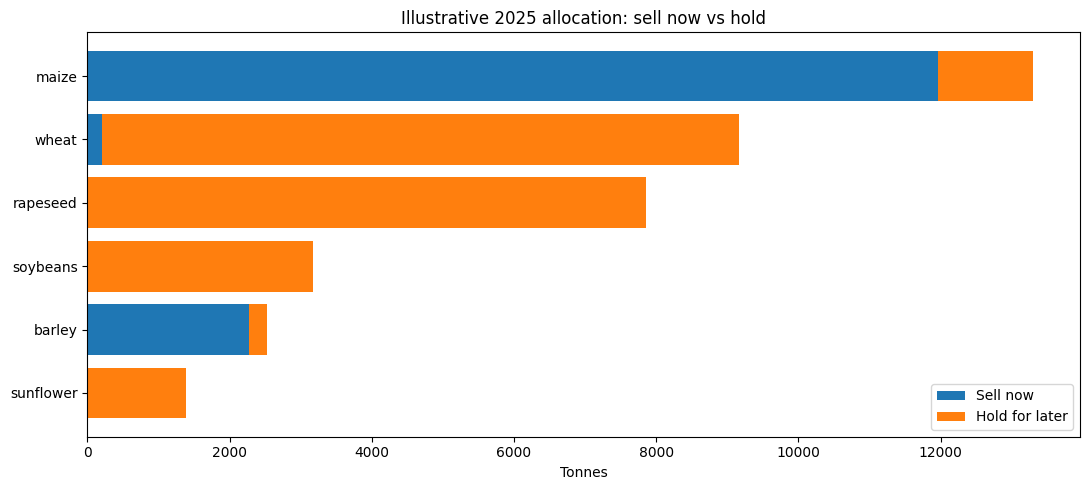

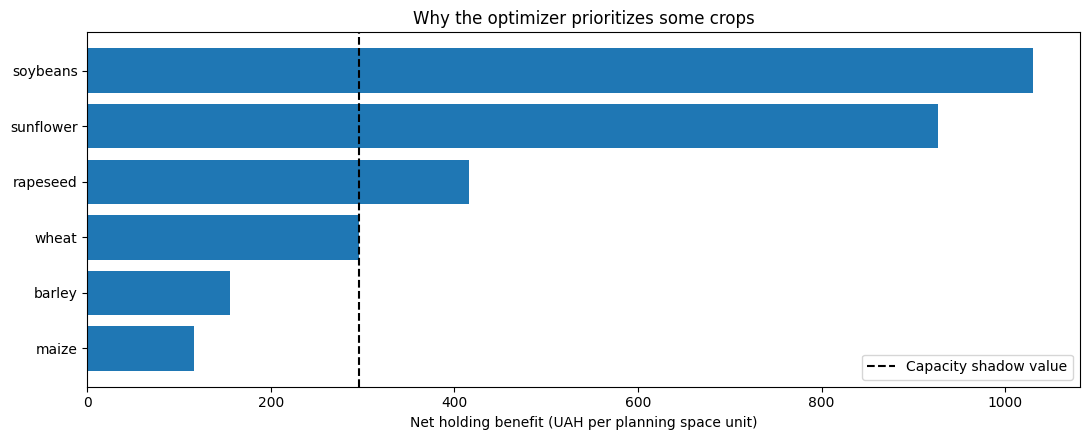

In [8]:
plt.style.use("default")
order = allocation.sort_values("available_tonnes", ascending=False).copy()
fig, ax = plt.subplots(figsize=(11,5))
y = np.arange(len(order))
ax.barh(y, order.sell_now_tonnes, label="Sell now")
ax.barh(y, order.hold_tonnes, left=order.sell_now_tonnes, label="Hold for later")
ax.set(yticks=y, yticklabels=order.crop, xlabel="Tonnes", title="Illustrative 2025 allocation: sell now vs hold")
ax.invert_yaxis(); ax.legend(); fig.tight_layout()
fig.savefig(OUT / "01_optimal_allocation.png", dpi=160, bbox_inches="tight")
plt.show()

fig,ax=plt.subplots(figsize=(11,4.5))
ordered=explain.sort_values("benefit_per_space_unit_uah")
ax.barh(ordered.crop, ordered.benefit_per_space_unit_uah)
ax.axvline(stats['capacity_shadow_value_uah_per_space_unit'], color='black', ls='--', linewidth=1.5, label='Capacity shadow value')
ax.set(xlabel="Net holding benefit (UAH per planning space unit)", title="Why the optimizer prioritizes some crops")
ax.legend(); fig.tight_layout()
fig.savefig(OUT / "02_marginal_benefits.png", dpi=160, bbox_inches="tight")
plt.show()

In [9]:
allocation.to_csv(OUT / "allocation_2025.csv", index=False, encoding="utf-8-sig")
explain.to_csv(OUT / "allocation_explainability.csv", index=False, encoding="utf-8-sig")
with (OUT / "model_assumptions.json").open("w", encoding="utf-8") as f:
    json.dump({"source_year":YEAR,"assumptions_are_illustrative":True,"market_price_source":None,
               "capacity_share_of_full_stock_space":CAPACITY_SHARE_OF_ALL_STOCK,
               "minimum_reserve_fraction":MIN_RESERVE_FRACTION,
               "crop_assumptions":ASSUMPTIONS},f,indent=2,ensure_ascii=False)
with (OUT / "optimization_summary.json").open("w", encoding="utf-8") as f:
    json.dump(stats, f,indent=2,ensure_ascii=False)
with (OUT / "optimization_summary.md").open("w", encoding="utf-8") as f:
    f.write(f"# Agricultural inventory optimization — illustrative {YEAR} scenario\\n\\n".replace('\\n','\n'))
    f.write("**Data:** crop stocks derived from the 50-сг accounting flows. **All prices, carrying costs, minimum reserves, space coefficients and capacity are illustrative assumptions, not observed facts or forecasts.**\n\n")
    f.write(f"- Crops: {len(allocation)}; available stock: {allocation.available_tonnes.sum():,.1f} tonnes.\n")
    f.write(f"- Hypothetical warehouse planning capacity: {stats['capacity_space_units']:,.1f} space units.\n")
    f.write(f"- Optimized net revenue: {stats['optimized_net_revenue_uah']:,.0f} UAH; gain vs feasible reserve-only baseline: {stats['optimized_net_revenue_uah']-reserve_only_net:,.0f} UAH.\n")
    f.write(f"- Capacity used: {stats['space_used_units']:,.1f} planning space units; shadow value: {stats['capacity_shadow_value_uah_per_space_unit']:,.2f} UAH per extra planning space unit.\n")
    f.write("- The deterministic model omits demand, price uncertainty, physical m³ and cash-flow constraints; do not apply as a real operational recommendation without external validation.\n")
print("Saved:")
for path in sorted(OUT.iterdir()): print(" ",path.name)

Saved:
  01_optimal_allocation.png
  02_marginal_benefits.png
  allocation_2025.csv
  allocation_explainability.csv
  model_assumptions.json
  optimization_summary.json
  optimization_summary.md
